# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$  Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$  Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Яндекс Книги: сравнение активности пользователей Москвы и Санкт-Петербурга

- Автор: Айнур Аймурзиева
- Дата: 19.09.2026

## Цели и задачи проекта

- рассчитать cреднее время активности пользователей в Санкт-Петербурге и в Москве
- оценить корректность проведения А/В-теста
- проанализировать результаты эксперимента

## Описание данных

Таблица `bookmate.audition` содержит данные об активности пользователей и состоит из следующих полей:
- `audition_id` — уникальный идентификатор сессии чтения или прослушивания;
- `puid` — идентификатор пользователя;
- `usage_platform_ru `— название платформы, с помощью которой пользователь слушал контент;
- `msk_business_dt_str` — дата события в формате строки (московское время);
- `app_version` — версия приложения, которая использовалась для чтения или прослушивания;
- `adult_content_flg` — был ли это контент для взрослых: True или False;
- `hours` — длительность чтения или прослушивания в часах;
- `hours_sessions_long` — продолжительность длинных сессий чтения или прослушивания в часах;
- `kids_content_flg` — был ли это детский контент: True или False;
- `main_content_id` — идентификатор основного контента;
- `usage_geo_id` — идентификатор географического местоположения.

Таблица `bookmate.content` содержит данные о контенте и состоит из следующих полей:
- `main_content_id` — идентификатор основного контента;
- `main_author_id` — идентификатор основного автора контента;
- `main_content_type` — тип контента;
- `main_content_name`— название контента;
- `main_content_duration_hours` — длительность контента в часах;
- `published_topic_title_list` — список жанров контента.

Таблица `bookmate.author` содержит данные об авторах контента и состоит из следующих полей:
- `main_author_id` — идентификатор основного автора контента;
- `main_author_name` — имя основного автора контента.

Таблица `bookmate.geo` содержит данные о местоположении и состоит из следующих полей:
- `usage_geo_id` — идентификатор географического положения;
- `usage_geo_id_name` — город или регион географического положения;
- `usage_country_name` — страна географического положения.

## Содержимое проекта

1. Загрузка данных и знакомство с ними
2. Проверить данные на дубликаты и пересечения. 

---

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest


In [2]:
knigi_test=pd.read_csv('/datasets/yandex_knigi_data.csv')

In [3]:
knigi_test=knigi_test.drop(columns='Unnamed: 0')

In [4]:
knigi_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   object 
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 206.0+ KB


In [5]:
knigi_test.describe()

,puid,hours
count,8.784000e+03,8784.000000
mean,1.029234e+13,11.087670
std,1.073532e+14,37.701350
min,9.668000e+03,0.000018
25%,3.239271e+08,0.066246
50%,8.828218e+08,0.942344
75%,1.516464e+09,6.065151
max,1.130000e+15,978.764775


## 2. Проверить данные на дубликаты и пересечения. 

In [6]:
# Проверка наличия дубликатов
knigi_test.duplicated().sum() 

0

In [7]:
# Проверяем неявные дубликаты
knigi_test.duplicated(subset=['puid']).sum() #244 дубликата

244

In [8]:
knigi_test.duplicated(subset=['puid', 'city']).sum()

0

In [9]:
# Проверяем неявные дубликаты
knigi_test.duplicated(subset=['puid']).sum() #244 дубликата

# Сохраняем id дублирующихся сессий
user_ids = knigi_test[knigi_test.duplicated(subset=['puid'])]['puid'].to_list()
knigi_test[ knigi_test['puid'].isin(user_ids)].sort_values(by=['puid', 'hours']).head(10)

,city,puid,hours
6247,Санкт-Петербург,2637041,3.883926
35,Москва,2637041,10.317371
6274,Санкт-Петербург,9979490,1.302997
134,Москва,9979490,32.415573
6279,Санкт-Петербург,10597984,9.041320
145,Москва,10597984,42.931506
6283,Санкт-Петербург,10815097,0.323291
150,Москва,10815097,9.086655
6300,Санкт-Петербург,13626259,1.648434
187,Москва,13626259,21.104167


In [10]:
g_M = knigi_test[knigi_test['city'] == 'Москва']['puid']
g_S = knigi_test[knigi_test['city'] == 'Санкт-Петербург']['puid']

intersection = list(set(g_M) & set(g_S))
print(intersection) 

len(intersection)

[439054848, 98068993, 84978689, 331188228, 59679749, 790564870, 40698887, 162106378, 1078819852, 1684058125, 1130000018954257, 959563282, 571554323, 1358054932, 313990163, 1778617878, 1210363415, 1316543509, 649885721, 1183963675, 1395494429, 1314529823, 1145886241, 1593760291, 1725564965, 24138278, 520518182, 363351088, 108083761, 570189363, 584447544, 860187201, 309104707, 550835780, 441112643, 1977784899, 1406501962, 528250442, 103543372, 1616171597, 589188176, 989693522, 1958805587, 401065555, 1557916755, 429727314, 1130000028554332, 488154206, 1965288031, 10597984, 9979490, 301108324, 1607495785, 767485035, 453988975, 912829040, 955554416, 1672056947, 819309176, 10815097, 196683896, 1076879993, 1974615673, 531369086, 1011254911, 555866239, 258809476, 66998918, 360290950, 1085783174, 236601993, 359740041, 998045836, 888840333, 2019864206, 1109631631, 1713008273, 317826707, 1236880533, 46837910, 1166679702, 137198745, 1891219106, 987817124, 1735154341, 176447657, 1748029097, 3793466

244

In [11]:
knigi_test = knigi_test.drop_duplicates(subset=['puid'])
knigi_test.duplicated(subset=['puid']).sum()

0

    
Явных дубликатов не обнаружено.
    
Среди 244 неявных дубликатов являются повторяющиеся пользователи в обоих регионах и с разной длительностью чтения. 

При этом выявлено 244 пользователя, которые одновременно присутствуют в разных группах теста. Такие пересечения нарушают независимость выборок и могут приводить к дисбалансу между группами и искажению результатов A/B-тестирования.
    
Дубликаты удалены для независимости выборок.
    
    

    
    

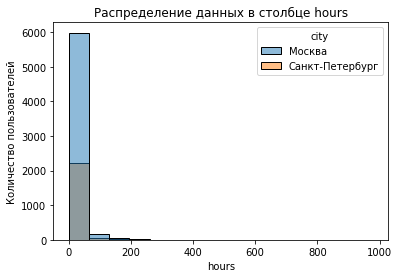

In [12]:
# Построим распределение данных в двух группах
sns.histplot(data=knigi_test, x='hours', bins=15, hue='city')

# Подписываем и отображаем график
plt.title('Распределение данных в столбце hours')
plt.ylabel('Количество пользователей')
plt.show()

Распределния обеих групп имеют правостороннюю асимметрию.

In [13]:
# Сравнение размеров групп, их статистики и распределения
group_size=knigi_test.groupby('city')['puid'].nunique()

group_size

city
Москва             6234
Санкт-Петербург    2306
Name: puid, dtype: int64

In [14]:
M=group_size['Москва']
S=group_size['Санкт-Петербург']

p=100*abs(M-S)/M

print(f'Процентная разница: {p}')

Процентная разница: 63.0093038177735


In [15]:
group_share= 100*group_size/knigi_test['puid'].nunique()

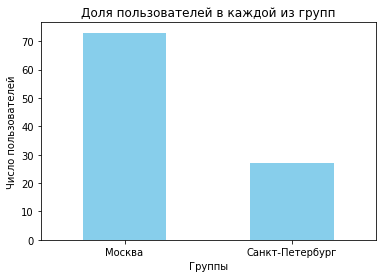

In [16]:
group_share.plot(kind='bar',
				title='Доля пользователей в каждой из групп',
                legend=False,
                ylabel='Число пользователей',
                xlabel='Группы',
				rot=0,
                color='skyblue')
plt.show()

Процентная разница составляет 63%. Такой дисбаланс между группами может повлиять на корректность и интерпретацию результатов A/B-тестирования.

In [17]:
hour_groups= knigi_test.groupby('city')['hours'].mean()
hour_groups

city
Москва             10.881092
Санкт-Петербург    11.264433
Name: hours, dtype: float64

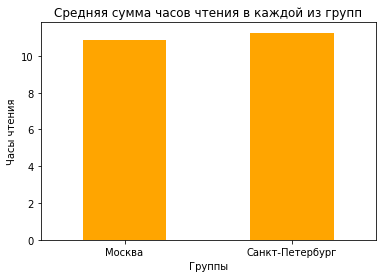

In [18]:
hour_groups.plot(kind='bar',
				title='Средняя сумма часов чтения в каждой из групп',
                legend=False,
                ylabel='Часы чтения',
                xlabel='Группы',
				rot=0,
                color='orange')
plt.show()

In [19]:
diff = hour_groups['Санкт-Петербург']-hour_groups['Москва']
print(f'Разница между двумя группами составляет {diff} часов')

Разница между двумя группами составляет 0.38334130357155516 часов


In [20]:
knigi_test.groupby('city')['hours'].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,6234.0,10.881092,36.851683,0.000018,0.059903,0.924498,5.939972,857.209373
Санкт-Петербург,2306.0,11.264433,39.831755,0.000025,0.060173,0.875355,6.138424,978.764775


 ### Вывод после проверки А/В-теста

Между группами наблюдается существенный дисбаланс. Разница в их размерах составляет около 63%. Это указывает на неоднородность выборок и может повлиять на достоверность результатов теста.
    
Выборки не являются полностью независимыми. Выявлено 244 пересечения пользователей между группами. Один и тот же пользователь может присутствовать в обеих группах, например, если он пользовался приложением из разных городов. Это нарушает независимость наблюдений и может повлиять на точность результатов.

Распределения в обеих группах имеют правостороннюю асимметрию, то есть не соответствуют нормальному распределению. Это следует учитывать при выборе статистического метода для сравнения групп.
    
Таким образом, при выборе статистического метода необходимо учитывать неравный размер групп, отсутствие нормальности распределения и нарушение независимости наблюдений.

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [21]:
# Проверка результатов А/В-теста
metric_a = knigi_test[knigi_test.city=='Москва']['hours'] 
metric_b = knigi_test[knigi_test.city=='Санкт-Петербург']['hours'] 

alpha = 0.05

stat_welch_ttest, p_value_welch_ttest = ttest_ind(
    metric_b,  # Санкт-Петербург
    metric_a,  # Москва

    equal_var=False,
    alternative='greater' 
) 
if p_value_welch_ttest>alpha:
    print(f'p-value теста Уэлча ={round(p_value_welch_ttest, 2)}')
    print(f'p-value > {alpha}')
    print('Нулевая гипотеза находит подтверждение! Нет оснований считать, что в Санкт-Петербурге среднее больше')
    print('Интерпретация: Cредняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается')
else:
    print(f'p-value теста Уэлча ={round(p_value_welch_ttest, 2)}')
    print(f'p-value < {alpha}')
    print('Нулевая гипотеза не находит подтверждения! Выборочные средние в группах A и B не равны, и в группе B больше')
    print('Интерпретация: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо')

p-value теста Уэлча =0.34
p-value > 0.05
Нулевая гипотеза находит подтверждение! Нет оснований считать, что в Санкт-Петербурге среднее больше
Интерпретация: Cредняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости.

- Результат теста, или p-value.

- Вывод на основе полученного p-value, то есть интерпретацию результатов.

- Одну или две возможные причины, объясняющие полученные результаты.

    
- Тип t-теста: разброс значений в группах сильно различается, лучше применить t-тест Уэлча, он не требует равенства дисперсий
- Уровень статистической значимости: alpha = 0.05
- p-value = 0.34 (p-value > 0.05)
- Поскольку p-value > 0,05, нет оснований отвергать нулевую гипотезу. Статистически значимых различий в средней активности пользователей в часах между Москвой и Санкт-Петербургом не выявлено.

Возможные причины результата:
- жители двух крупнейших городов имеют схожий образ жизни и бытовые привычки, поэтому их поведение в приложении похоже;
- распределение активности сильно скошено вправо: у большинства пользователей несколько часов, а средние определяются небольшим числом очень активных читателей. Из-за большого разброса небольшая разница средних (около 0.4 часа) не выделяется на фоне шума.

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.

- загрузить данные теста;

- проверить корректность его проведения;

- проанализировать полученные результаты.

Гипотеза заключается в следующем: упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится как минимум на три процентных пункта.

Параметры теста:

название теста: interface_eu_test;

группы: А (контрольная), B (новый интерфейс).

Данные
`https://code.s3.yandex.net/datasets/ab_test_participants.csv` — таблица участников тестов.
Структура файла:
- `user_id` — идентификатор пользователя;
- `group` — группа пользователя;
- `ab_test` — название теста;
- `device` — устройство, с которого происходила регистрация.

`https://code.s3.yandex.net/datasets/ab_test_events.zip` — архив с одним csv-файлом, в котором собраны события 2020 года;
Структура файла:
- `user_id` — идентификатор пользователя;
- `event_dt` — дата и время события;
- `event_name` — тип события;
- `details` — дополнительные данные о событии.

## 2. Загрузите данные, оцените их целостность.

In [22]:
# Cчитываем датафреймы
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [23]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [24]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


In [25]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [26]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


In [27]:
events[events['user_id'] == 'GLOBAL'].shape[0]

58495

In [28]:
events[events['user_id'] == 'GLOBAL']['event_name'].value_counts()

product_page                          33166
purchase                              15520
product_cart                           9806
Start of Christmas&New Year Promo         1
End of Black Friday Ads Campaign          1
Start of CIS New Year Gift Lottery        1
Name: event_name, dtype: int64

Пропуски выявлены в столбце `details`. Поскольку этот столбец содержит дополнительную информацию о событиях, отсутствие значений допустимо, так как не для каждого события предусмотрены дополнительные данные. Кроме того, столбец `details` не используется в дальнейшем анализе, поэтому пропуски можно оставить без изменений.

В столбце `user_id` обнаружено 58 495 строк со значением `GLOBAL`. Эти записи не связаны с конкретными пользователями. Поэтому при формировании выборки участников A/B-теста их можно исключить вместе с другими событиями, которые не относятся к пользователям исследуемой выборки.

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [29]:
# Проверка на дубликаты
participants.duplicated().sum() 

0

In [30]:
participants['ab_test'].unique()

array(['interface_eu_test', 'recommender_system_test'], dtype=object)

In [31]:
# Проверка на пересечение
eu_test = participants[participants['ab_test'] == 'interface_eu_test']['user_id']
system_test = participants[participants['ab_test'] == 'recommender_system_test']['user_id']

intersection = list(set(eu_test) & set(system_test))
print(intersection)

['C21237DC47AE00C5', '958426148AFA05C5', '2A12B7DB3C6E84D6', 'CA9D3DEA00836355', 'A1C3D3C6C3CADDC5', 'A8533224E9384B16', 'F7E2CAFE32DB0B14', '48CFE37563932DC2', '0D6F5E157A56FB00', '11C52432A6F7FA6B', 'C41BBCA9DACE544D', '788C61EDBDD38346', '13AE4DFAC67ACEB3', '9E68AB5C5C7FEFF4', '6B72CFAE1935C789', '3D264F3D953DBA67', '5A26996E38367C70', 'DD4352CDCF8C3D57', 'A76F046D8D47589E', '6ED57949BDA6D94E', '68B3C70F0C0B4550', 'B42748BA986E4163', '6A2064F288EF094F', 'DF40EF85F55A958D', 'AA5A1803D3FA76B4', '4F26C1C82B9EA0B5', '16F2DB656CC2F952', '3E286601D309601C', '8C66932374EF8009', '5C7F53937B54D161', '0DB417842D3B79A2', '8FA915CDB5994BDC', 'F0B92123E5142CBB', '46A7B6A9C1C4E46B', 'DABC08CC80316871', 'ECC76B90EB71C492', '11970FE3A608F9EF', '3D89F6FEA1926F70', 'D2F6FB926A64D196', '94464DF2E5398E26', '4DBBBAA6705078D0', '9657A8EEFB5E37E5', '1D9020D7979F924A', '49D69A4901413D82', 'D3A4F3513CC0AA2F', '676A58D41A3E0A47', '0C2FF828F063B7AD', 'B8AC521CB28510E7', '7A4A6B4CC6FDB0FF', 'C573C24EF423143C',

In [32]:
len(intersection)

887

In [33]:
# Создаем датафрейм участников теста
ab_test_participants = participants[~(participants['user_id'].isin(intersection)) & (participants['ab_test']!='recommender_system_test')]

In [34]:
group_count=ab_test_participants.groupby('group')['user_id'].nunique()
group_count

group
A    4952
B    5011
Name: user_id, dtype: int64

In [35]:
group_share=100 * group_count/ ab_test_participants['user_id'].nunique()
group_share

group
A    49.703904
B    50.296096
Name: user_id, dtype: float64

3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [36]:
ab_test_events=events[events['user_id'].isin(ab_test_participants['user_id'])]

- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [37]:
ab_test_events['event_name'].unique()

array(['registration', 'login', 'product_page', 'purchase',
       'product_cart'], dtype=object)

In [38]:
registration_dates = ab_test_events[ab_test_events['event_name'] == 'registration'].groupby('user_id')['event_dt'].min().rename('registration_dt')
registration_dates

user_id
0002CE61FF2C4011   2020-12-07 04:37:31
001E72F50D1C48FA   2020-12-17 15:44:05
002412F1EB3F6E38   2020-12-09 09:36:50
002540BE89C930FB   2020-12-08 18:06:07
0031F1B5E9FBF708   2020-12-14 00:47:10
                           ...        
FFE5B14BD55C1C5C   2020-12-19 06:27:24
FFE600EEC4BA7685   2020-12-13 21:43:31
FFE7FC140521F5F6   2020-12-23 09:10:16
FFEFC0E55C1CCD4F   2020-12-13 23:52:15
FFF58BC33966EB51   2020-12-13 17:37:34
Name: registration_dt, Length: 9963, dtype: datetime64[ns]

In [39]:
ab_test_events=ab_test_events.merge(registration_dates, on='user_id', how='left')
ab_test_events.head()

,user_id,event_dt,event_name,details,registration_dt
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20


In [40]:
ab_test_events['lifetime']=(ab_test_events['event_dt']-ab_test_events['registration_dt'])
ab_test_events

,user_id,event_dt,event_name,details,registration_dt,lifetime
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0 days 00:00:00
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0 days 00:00:00
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0 days 00:00:00
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0 days 00:00:00
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0 days 00:00:00
...,...,...,...,...,...,...
73810,F80C9BDDEA02E53C,2020-12-30 10:02:43,purchase,4.49,2020-12-07 10:05:54,22 days 23:56:49
73811,F80C9BDDEA02E53C,2020-12-30 10:03:51,purchase,4.49,2020-12-07 10:05:54,22 days 23:57:57
73812,F80C9BDDEA02E53C,2020-12-30 10:03:52,product_cart,NaN,2020-12-07 10:05:54,22 days 23:57:58
73813,6181F3835EBE66BF,2020-12-30 12:10:39,product_cart,NaN,2020-12-07 19:53:20,22 days 16:17:19


In [42]:
ab_test_events=ab_test_events[ab_test_events['lifetime']<= pd.to_timedelta('7 D')]

Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [44]:

# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2 # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 3761


- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [45]:
# Создаем общий датафрейм по А/В-тесту
ab_test = ab_test_events.merge(ab_test_participants[['user_id', 'group']], on='user_id',how='left')
ab_test

,user_id,event_dt,event_name,details,registration_dt,lifetime,group
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0 days 00:00:00,A
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0 days 00:00:00,A
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0 days 00:00:00,B
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0 days 00:00:00,A
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0 days 00:00:00,B
...,...,...,...,...,...,...,...
63800,E89AF4EFC757D283,2020-12-29 21:46:43,product_cart,NaN,2020-12-23 09:35:48,6 days 12:10:55,A
63801,E89AF4EFC757D283,2020-12-29 21:47:56,product_cart,NaN,2020-12-23 09:35:48,6 days 12:12:08,A
63802,A6AFDC94A0D3B23D,2020-12-29 22:47:00,product_page,NaN,2020-12-23 13:53:33,6 days 08:53:27,A
63803,A6AFDC94A0D3B23D,2020-12-29 22:48:46,product_page,NaN,2020-12-23 13:53:33,6 days 08:55:13,A


In [46]:
purchase_user=ab_test[ab_test['event_name']=='purchase'].groupby('group')['user_id'].nunique()
purchase_user

group
A    1377
B    1480
Name: user_id, dtype: int64

In [47]:
all_users=ab_test.groupby('group')['user_id'].nunique()
all_users

group
A    4952
B    5011
Name: user_id, dtype: int64

In [48]:
purchase_share=100*purchase_user/all_users
purchase_share

group
A    27.806947
B    29.535023
Name: user_id, dtype: float64

In [49]:
difference=round(purchase_share['B']-purchase_share['A'], 2)
print(f'Процентная разница: {difference}')

Процентная разница: 1.73


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

Покупательская активность в тестовой группе B выше, чем в контрольной группе A, на 1.73 процентных пунктов.
    
Однако наблюдаемое увеличение конверсии не достигает целевого прироста в 3 п.п.

 

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

- Нулевая гипотеза H₀: конверсия зарегистрированных пользователей в покупателей в группе B (новый интерфейс) не выше, чем в группе A.

- Альтернативная гипотеза H₁: конверсия в группе B выше, чем в группе A, и это различие статистически значимо.

Единица анализа — пользователь: считаем долю уникальных пользователей, совершивших хотя бы одну покупку в первые 7 дней после регистрации.

In [50]:
# Размеры групп — уникальные пользователи
n_a = ab_test[ab_test.group == 'A']['user_id'].nunique()
n_b = ab_test[ab_test.group == 'B']['user_id'].nunique()

# Количество пользователей, совершивших хотя бы одну покупку
m_a = ab_test[(ab_test.group == 'A') & (ab_test.event_name == 'purchase')]['user_id'].nunique()
m_b = ab_test[(ab_test.group == 'B') & (ab_test.event_name == 'purchase')]['user_id'].nunique()

p_a, p_b = m_a / n_a, m_b / n_b

# Проверка предпосылки о достаточном количестве данных
if (p_a*n_a > 10) and ((1-p_a)*n_a > 10) and (p_b*n_b > 10) and ((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

alpha = 0.05

# Односторонний Z-тест пропорций: H1 — конверсия в A меньше, чем в B
stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller'
)

print(f'p_value={p_value_ztest:.4f}')

if p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение!')
else:
    print('Нулевая гипотеза не находит подтверждения!')

print(f'Конверсия: A = {p_a:.2%}, B = {p_b:.2%}, разница = {(p_b - p_a)*100:.2f} п.п.')


Предпосылка о достаточном количестве данных выполняется!
p_value=0.0283
Нулевая гипотеза не находит подтверждения!
Конверсия: A = 27.81%, B = 29.54%, разница = 1.73 п.п.


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

- В анализ вошли 9 963 пользователя: группа A — 4 952, группа B — 5 011. Группы сбалансированы (49.7% / 50.3%), пересечения с конкурирующим тестом исключены.

- Конверсия в покупку за 7 дней после регистрации: группа A — 27.81%, группа B — 29.54%. Прирост — 1.73 п.п.

- Односторонний Z-тест пропорций: p-value ≈ 0.028 < 0.05, нулевая гипотеза отвергается. Рост конверсии в группе B статистически значим.

- Однако ожидаемый эффект не достигнут: прирост 1.73 п.п. меньше целевых 3 п.п. Кроме того, тест рассчитывался на MDE 3 п.п., поэтому для надёжной оценки эффекта такого размера выборка недостаточна.

- Рекомендация: новый интерфейс не ухудшает метрику и даёт небольшой положительный эффект, его можно внедрять, если стоимость поддержки невысока. Чтобы добиться целевого роста на 3 п.п., стоит изучить воронку (регистрация → карточка товара → корзина → покупка), найти этап с наибольшими потерями, доработать его и провести повторный тест.